# Shock-location transfer for a nozzle PINN: pretrained weights + LoRA vs. train-from-base

**Problem.** Quasi-1D converging–diverging nozzle, unsteady Euler equations marched in pseudo-time to steady state.
A normal shock sits at a location fixed by the back pressure. The shock is handled with two sub-networks
(`net_L` upstream, `net_R` downstream) joined by Rankine–Hugoniot conditions at a learnable shock position.

**Question.** Once a model exists for shock at `x_pre`, how cheaply can we get a model for a *different*
shock location `x_new` (new back pressure)?

```
  Coarse single-net  ──(same as fresh, at x_new)──►  shock estimate x0 ─┐
                                                                        ▼
  Pretrained dual nets (x_pre)  ──[TL]──────────────────────────►  Dual loop with LoRA adapters    ─┐
                                                                                                    ├─ compare
  Coarse net (random init) ──► Dual loop, all weights trained  ("train-from-base") ─────────────────┘
```

| arm | dual-net init | trainable |
|---|---|---|
| `base` | clone of the fresh coarse net (this is the original notebook's pipeline) | all weights |
| `tl_full` *(ablation)* | pretrained dual nets from `x_pre` | all weights |
| `tl_lora_r{r}` | pretrained dual nets from `x_pre`, frozen | rank-`r` LoRA adapters only |

**Metrics are hardware-independent**: accuracy against the analytic solution, physics residuals, and cost
counted in *residual evaluations* and *trainable parameters* — not wall-clock.

**How to run.** Set `PRESET` in the config cell (`"smoke"` → checks the plumbing in ~1 min, `"quick"` → small budget,
`"full"` → the budgets from the original notebook). Everything is cached under `runs/`, keyed by a hash of the
config, so re-running a cell only retrains what changed.

## 1. Setup and configuration

In [1]:
import hashlib
import json
import math
import os
import random
import time
from copy import deepcopy
from dataclasses import asdict, dataclass, field, replace
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from scipy.optimize import brentq

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# --- fixed physics (not hyper-parameters) ------------------------------------------------------
GAMMA = 1.4
X_START, X_THROAT, X_END = 0.0, 0.5, 1.0
BD_DELTA = 1e-5  # mask width for boundary / IC point selection

In [2]:
PRESET = os.environ.get("PINN_PRESET", "quick")  # "smoke" | "quick" | "full"


@dataclass(frozen=True)
class Config:
    # -- experiment ---------------------------------------------------------------------------
    x_pre: float = 0.75  # shock location of the pretrained model
    x_new: float = 0.90  # shock location of the new case
    pre_seed: int = 1
    seeds: tuple = (0, 1, 2)  # seeds for the x_new runs (pretrained model is a single fixed asset)
    lora_ranks: tuple = (4,)
    lora_alpha: float | None = None  # default: alpha = rank  (scaling 1)
    lora_lr: float | None = None  # default: same as dual_lr
    run_tl_full: bool = True  # ablation arm: pretrained init, all weights trainable
    # -- network ------------------------------------------------------------------------------
    hid_dim: int = 128
    num_hidden: int = 3
    t_max: float = 5.0  # pseudo-time at which the steady state is read off
    # -- coarse single-net stage ("shock detection") -------------------------------------------
    coarse_points: int = 2000
    coarse_adam_epochs: int = 1500
    coarse_lbfgs_epochs: int = 1000
    coarse_lr: float = 1e-3
    coarse_resample_every: int = 500
    coarse_bc_weight: float = 10.0
    shock_formation_tol: float = 1e-1
    # -- dual-net stage -----------------------------------------------------------------------
    dual_points: int = 1000
    dual_time_samples: int = 200
    dual_adam_epochs: int = 6000
    dual_lbfgs_epochs: int = 1000
    dual_lr: float = 1e-3
    shock_lr: float = 1e-4
    dual_resample_every: int = 1000
    dual_lbfgs_resample_every: int = 500
    remesh_every: int = 600
    remesh_tol: float = 1e-3
    bc_weight: float = 10.0
    interface_weight: float = 10.0
    prior_weight: float = 5.0  # soft pull of the shock towards the value implied by the back pressure
    # -- shared -------------------------------------------------------------------------------
    grad_clip: float = 1.0
    max_consecutive_nan: int = 5
    print_every: int = 500
    # -- evaluation ---------------------------------------------------------------------------
    n_eval: int = 2000
    eval_every_evals: int = 100  # record accuracy every N residual evaluations
    shock_band: float = 0.05  # half-width excluded around shocks for "smooth-region" error
    # -- IO -----------------------------------------------------------------------------------
    run_dir: str = "runs"
    force_retrain: bool = False

    # fields that do not change what a trained model looks like -> excluded from cache hashes
    _NON_TRAINING = ("seeds", "lora_ranks", "run_tl_full", "eval_every_evals", "shock_band",
                     "n_eval", "run_dir", "force_retrain", "print_every")

    def tag(self, **extra) -> str:
        d = {k: v for k, v in asdict(self).items() if k not in self._NON_TRAINING}
        d.update(extra)
        return hashlib.md5(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:10]

    @staticmethod
    def preset(name: str) -> "Config":
        if name == "full":
            return Config()
        if name == "quick":
            return Config(
                coarse_points=1000, coarse_adam_epochs=1500, coarse_lbfgs_epochs=60,
                dual_points=500, dual_time_samples=100, dual_adam_epochs=3000, dual_lbfgs_epochs=60,
                dual_resample_every=500, dual_lbfgs_resample_every=30, remesh_every=300,
                coarse_resample_every=250, print_every=500, eval_every_evals=50,
                seeds=(0, 1), lora_ranks=(4, 16),
            )
        if name == "smoke":
            return Config(
                coarse_points=200, coarse_adam_epochs=40, coarse_lbfgs_epochs=3,
                dual_points=200, dual_time_samples=40, dual_adam_epochs=60, dual_lbfgs_epochs=3,
                dual_resample_every=30, dual_lbfgs_resample_every=3, remesh_every=30,
                coarse_resample_every=20, print_every=20, eval_every_evals=10,
                seeds=(0,), lora_ranks=(4,), hid_dim=32, num_hidden=2,
            )
        raise ValueError(f"unknown preset {name!r}")


CFG = Config.preset(PRESET)
print(f"device={DEVICE}  preset={PRESET}")
print(CFG)

device=cpu  preset=quick
Config(x_pre=0.75, x_new=0.9, pre_seed=1, seeds=(0, 1), lora_ranks=(4, 16), lora_alpha=None, lora_lr=None, run_tl_full=True, hid_dim=128, num_hidden=3, t_max=5.0, coarse_points=1000, coarse_adam_epochs=1500, coarse_lbfgs_epochs=60, coarse_lr=0.001, coarse_resample_every=250, coarse_bc_weight=10.0, shock_formation_tol=0.1, dual_points=500, dual_time_samples=100, dual_adam_epochs=3000, dual_lbfgs_epochs=60, dual_lr=0.001, shock_lr=0.0001, dual_resample_every=500, dual_lbfgs_resample_every=30, remesh_every=300, remesh_tol=0.001, bc_weight=10.0, interface_weight=10.0, prior_weight=5.0, grad_clip=1.0, max_consecutive_nan=5, print_every=500, n_eval=2000, eval_every_evals=50, shock_band=0.05, run_dir='runs', force_retrain=False)


## 2. Physics: nozzle, analytic reference, problem definition
`Problem(x_shock)` bundles everything that depends on the shock location: back pressure, inlet state and the
analytic steady solution. Losses take a `Problem` explicitly (the original notebook monkey-patched globals).

In [3]:
def area(x):
    return 1.0 + 2.2 * (x - X_THROAT) ** 2


def d_area(x):
    return 4.4 * (x - X_THROAT)


def _area_mach_ratio(M: float) -> float:
    t = 1.0 + 0.5 * (GAMMA - 1.0) * M**2
    return (1.0 / M) * (2.0 / (GAMMA + 1.0) * t) ** ((GAMMA + 1.0) / (2.0 * (GAMMA - 1.0)))


def mach_from_area(a: float, supersonic: bool) -> float:
    """Invert the isentropic area–Mach relation."""
    if a <= 1.0 + 1e-12:
        return 1.0
    lo, hi = (1.0 + 1e-9, 60.0) if supersonic else (1e-6, 1.0 - 1e-9)
    return brentq(lambda M: _area_mach_ratio(M) - a, lo, hi)


def normal_shock(M1: float) -> tuple[float, float]:
    """(M2, p02/p01) across a normal shock."""
    g = GAMMA
    M2 = math.sqrt((1 + 0.5 * (g - 1) * M1**2) / (g * M1**2 - 0.5 * (g - 1)))
    rho_ratio = (g + 1) * M1**2 / ((g - 1) * M1**2 + 2)
    p02_p01 = rho_ratio ** (g / (g - 1)) * ((g + 1) / (2 * g * M1**2 - (g - 1))) ** (1 / (g - 1))
    return M2, p02_p01


class Problem:
    """Steady nozzle flow with a normal shock at `x_shock` (stagnation state p0 = T0 = rho0 = 1 upstream)."""

    def __init__(self, x_shock: float):
        self.x_shock = float(x_shock)
        # inlet (subsonic, isentropic)
        self.M_in = mach_from_area(float(area(X_START)), supersonic=False)
        t_in = 1.0 + 0.5 * (GAMMA - 1.0) * self.M_in**2
        self.rho_in = t_in ** (-1.0 / (GAMMA - 1.0))
        self.T_in = 1.0 / t_in
        self.P_in = self.rho_in * self.T_in
        self.u_in = self.M_in * math.sqrt(GAMMA * self.T_in)
        # shock + back pressure
        self.M1 = mach_from_area(float(area(self.x_shock)), supersonic=True)
        self.M2, self.p02_p01 = normal_shock(self.M1)
        M_exit = mach_from_area(max(float(area(X_END)) * self.p02_p01, 1.0 + 1e-6), supersonic=False)
        t_exit = 1.0 + 0.5 * (GAMMA - 1.0) * M_exit**2
        self.p_exit = self.p02_p01 * t_exit ** (-GAMMA / (GAMMA - 1.0))

    def reference(self, x: np.ndarray) -> dict[str, np.ndarray]:
        """Analytic steady-state fields on grid x."""
        x = np.asarray(x, dtype=float)
        A = area(x)
        M = np.empty_like(x)
        for i, (xi, Ai) in enumerate(zip(x, A)):
            if xi <= X_THROAT:
                M[i] = mach_from_area(Ai, supersonic=False)
            elif xi <= self.x_shock:
                M[i] = mach_from_area(Ai, supersonic=True)
            else:
                M[i] = mach_from_area(Ai * self.p02_p01, supersonic=False)
        P0 = np.where(x > self.x_shock, self.p02_p01, 1.0)
        t = 1.0 + 0.5 * (GAMMA - 1.0) * M**2
        T = 1.0 / t
        P = P0 * t ** (-GAMMA / (GAMMA - 1.0))
        rho = P0 * t ** (-1.0 / (GAMMA - 1.0))
        u = M * np.sqrt(GAMMA * T)
        return dict(rho=rho, u=u, P=P, T=T, M=M)

    def __repr__(self):
        return (f"Problem(x_shock={self.x_shock:.3f}, p_exit={self.p_exit:.4f}, "
                f"M1={self.M1:.3f}, M2={self.M2:.3f}, p02/p01={self.p02_p01:.4f})")


PROB_PRE, PROB_NEW = Problem(CFG.x_pre), Problem(CFG.x_new)
print(PROB_PRE)
print(PROB_NEW)

# sanity: the analytic solution reproduces the back pressure used in the BC
for _p in (PROB_PRE, PROB_NEW):
    assert abs(_p.reference(np.array([X_END]))["P"][0] - _p.p_exit) < 1e-6

Problem(x_shock=0.750, p_exit=0.8289, M1=1.439, M2=0.724, p02/p01=0.9478)
Problem(x_shock=0.900, p_exit=0.7101, M1=1.715, M2=0.637, p02/p01=0.8494)


## 3. Networks: base MLP, LoRA wrapper, dual model
* `UnsteadyNet`: `(x, t) → (ρ, u, P, T)`.
* `LoRALinear` freezes a `Linear` and adds `scaling · B·A`. `B = 0` at init, so wrapping is an exact warm start.
* `to_plain` folds adapters back into ordinary weights (for deployment / checkpoint-agnostic reuse).
* `DualModel` = `(net_L, net_R, shock)`; it knows how to derive a (LoRA) copy of itself for a new shock location.

In [4]:
class UnsteadyNet(nn.Module):
    INPUT, OUTPUT = 2, 4

    def __init__(self, hid_dim: int = 128, num_hidden: int = 3):
        super().__init__()
        self.hid_dim, self.num_hidden = hid_dim, num_hidden
        layers = [nn.Linear(self.INPUT, hid_dim), nn.Tanh()]
        for _ in range(num_hidden):
            layers += [nn.Linear(hid_dim, hid_dim), nn.Tanh()]
        layers += [nn.Linear(hid_dim, self.OUTPUT)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="tanh")
                nn.init.zeros_(m.bias)

    def forward(self, xt: torch.Tensor) -> torch.Tensor:
        out = nn.functional.softplus(self.net(xt) + 1.0)  # positive (rho, u, P, T)
        return out


class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, rank: int, alpha: float | None = None):
        super().__init__()
        assert rank > 0
        self.in_features, self.out_features, self.rank = base.in_features, base.out_features, rank
        self.alpha = float(alpha) if alpha is not None else float(rank)
        self.scaling = self.alpha / rank
        self.weight = nn.Parameter(base.weight.detach().clone(), requires_grad=False)
        self.bias = nn.Parameter(base.bias.detach().clone(), requires_grad=False)
        self.lora_A = nn.Parameter(torch.empty(rank, self.in_features))
        self.lora_B = nn.Parameter(torch.zeros(self.out_features, rank))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))

    def effective_weight(self) -> torch.Tensor:
        return self.weight + self.scaling * (self.lora_B @ self.lora_A)

    def forward(self, x):
        return nn.functional.linear(x, self.weight, self.bias) + self.scaling * nn.functional.linear(
            nn.functional.linear(x, self.lora_A), self.lora_B)


def apply_lora(model: UnsteadyNet, rank: int, alpha: float | None = None) -> UnsteadyNet:
    """In place: wrap every Linear in `model.net` with a LoRALinear."""
    if has_lora(model):
        raise ValueError("model already has LoRA adapters; call to_plain() first")
    model.net = nn.Sequential(*[LoRALinear(m, rank, alpha) if isinstance(m, nn.Linear) else m for m in model.net])
    return model.to(DEVICE)


def has_lora(model: nn.Module) -> bool:
    return any(isinstance(m, LoRALinear) for m in model.modules())


def lora_parameters(model: nn.Module) -> list[nn.Parameter]:
    return [p for n, p in model.named_parameters() if "lora_" in n]


def lora_config(model: nn.Module) -> dict | None:
    for m in model.modules():
        if isinstance(m, LoRALinear):
            return {"rank": m.rank, "alpha": m.alpha}
    return None


@torch.no_grad()
def to_plain(model: UnsteadyNet) -> UnsteadyNet:
    """New ordinary UnsteadyNet holding the model's *effective* weights (adapters folded in). Never mutates `model`."""
    plain = UnsteadyNet(model.hid_dim, model.num_hidden).to(DEVICE)
    for dst, src in zip(plain.net, model.net):
        if isinstance(src, LoRALinear):
            dst.weight.copy_(src.effective_weight())
            dst.bias.copy_(src.bias)
        elif isinstance(src, nn.Linear):
            dst.weight.copy_(src.weight)
            dst.bias.copy_(src.bias)
    return plain


def add_lora(source: UnsteadyNet, rank: int, alpha: float | None = None) -> UnsteadyNet:
    """Copy of `source` (frozen) + fresh rank-`rank` adapters."""
    return apply_lora(to_plain(source), rank, alpha)


def count_params(*modules: nn.Module) -> tuple[int, int]:
    """(trainable, total)"""
    ps = [p for m in modules for p in m.parameters()]
    return sum(p.numel() for p in ps if p.requires_grad), sum(p.numel() for p in ps)


class ShockParam(nn.Module):
    def __init__(self, x: float):
        super().__init__()
        self.x_shock = nn.Parameter(torch.tensor([float(x)]))

    def clamped_x(self) -> torch.Tensor:
        return self.x_shock.clamp(X_THROAT + BD_DELTA, X_END - BD_DELTA)


@dataclass
class DualModel:
    net_L: UnsteadyNet
    net_R: UnsteadyNet
    shock: ShockParam

    @property
    def x_shock(self) -> float:
        return self.shock.clamped_x().item()

    @classmethod
    def from_single(cls, model: UnsteadyNet, x_shock: float) -> "DualModel":
        """Both sub-nets start as copies of one (coarse) network — the original notebook's initialisation."""
        return cls(to_plain(model), to_plain(model), ShockParam(x_shock).to(DEVICE))

    def derive(self, x_shock: float, lora_rank: int | None = None, lora_alpha: float | None = None) -> "DualModel":
        """New DualModel starting from this one's weights (transfer learning), shock re-initialised at `x_shock`."""
        mk = (lambda n: add_lora(n, lora_rank, lora_alpha)) if lora_rank else to_plain
        return DualModel(mk(self.net_L), mk(self.net_R), ShockParam(x_shock).to(DEVICE))

    def full_params(self) -> list[nn.Parameter]:
        return list(self.net_L.parameters()) + list(self.net_R.parameters())

    def trainable_params(self) -> list[nn.Parameter]:
        """Params the dual loop updates for the nets: adapters if LoRA-wrapped, else all weights."""
        if has_lora(self.net_L):
            return lora_parameters(self.net_L) + lora_parameters(self.net_R)
        return self.full_params()

    def n_params(self) -> tuple[int, int]:
        tr, tot = count_params(self.net_L, self.net_R)
        return tr + 1, tot + 1  # + shock location

## 4. Sampling and losses

In [5]:
def sample_points(x_low: float, x_high: float, n: int, t_max: float, ic_frac=0.05, bc_frac=0.05) -> torch.Tensor:
    """Interior + inlet(x=x_low) + outlet(x=x_high) + IC(t=0) collocation points, shuffled, requires_grad."""
    n_ic, n_bc = max(1, int(n * ic_frac)), max(1, int(n * bc_frac))
    n_int = n - 2 * n_bc - n_ic
    rnd = lambda k: torch.rand(k, 1, device=DEVICE)
    xt = torch.cat([
        torch.cat([rnd(n_int) * (x_high - x_low) + x_low, rnd(n_int) * t_max], 1),
        torch.cat([torch.full((n_bc, 1), x_low, device=DEVICE), rnd(n_bc) * t_max], 1),
        torch.cat([torch.full((n_bc, 1), x_high, device=DEVICE), rnd(n_bc) * t_max], 1),
        torch.cat([rnd(n_ic) * (x_high - x_low) + x_low, torch.zeros(n_ic, 1, device=DEVICE)], 1),
    ])
    return xt[torch.randperm(xt.shape[0], device=DEVICE)].requires_grad_(True)


def _grad(f: torch.Tensor, xt: torch.Tensor):
    g = torch.autograd.grad(f.sum(), xt, create_graph=True)[0]
    return g[:, 0:1], g[:, 1:2]


def pde_residual(model: nn.Module, xt: torch.Tensor) -> torch.Tensor:
    """Quasi-1D Euler residuals [mass, momentum, energy, ideal-gas], shape (N, 4)."""
    out = model(xt)
    rho, u, P, T = out[:, 0:1], out[:, 1:2], out[:, 2:3], out[:, 3:4]
    x = xt[:, 0:1]
    A, A_x = area(x), d_area(x)
    rho_x, rho_t = _grad(rho, xt)
    u_x, u_t = _grad(u, xt)
    P_x, _ = _grad(P, xt)
    T_x, T_t = _grad(T, xt)
    mass = A * rho_t + A * u * rho_x + A * rho * u_x + rho * u * A_x
    momentum = A * (rho * (u_t + u * u_x) + P_x)
    energy = rho * A * (T_t + u * T_x) + (GAMMA - 1.0) * P * (A * u_x + A_x * u)
    ideal = P - rho * T
    return torch.cat([mass, momentum, energy, ideal], dim=1)


def bc_loss(model: nn.Module, xt: torch.Tensor, prob: Problem, side: str = "all") -> torch.Tensor:
    """Soft BCs as MSE penalties on the boundary points present in `xt`.

    inlet (x≈0): full inlet state;  outlet (x≈1): P = p_exit;  IC (t≈0): inlet thermodynamic state, u = 0.
    side: "left"  -> inlet + IC          (upstream sub-network, domain [0, x_shock])
          "right" -> outlet + IC         (downstream sub-network, domain [x_shock, 1])
          "all"   -> inlet + outlet + IC (single coarse network over the whole nozzle)
    The inlet needs t ≥ δ and the IC needs δ ≤ x ≤ 1−δ, so each corner point is assigned to one condition
    only (inlet wins at x=0, outlet at x=1) instead of two contradictory ones."""
    if side not in ("left", "right", "all"):
        raise ValueError(f"side must be 'left', 'right' or 'all', got {side!r}")
    out = model(xt)
    rho, u, P, T = out[:, 0], out[:, 1], out[:, 2], out[:, 3]
    x, t = xt[:, 0], xt[:, 1]
    zero = torch.zeros((), device=DEVICE)
    sq = lambda v: v.pow(2).mean()

    m_in = (x < BD_DELTA) & (t >= BD_DELTA)
    m_ic = (t < BD_DELTA) & (x >= BD_DELTA) & (x <= X_END - BD_DELTA)
    m_out = x > X_END - BD_DELTA

    inlet = (sq(rho[m_in] / prob.rho_in - 1) + sq(u[m_in] - prob.u_in) + sq(P[m_in] / prob.P_in - 1)
             + sq(T[m_in] / prob.T_in - 1)) if m_in.any() else zero
    outlet = sq(P[m_out] / prob.p_exit - 1) if m_out.any() else zero
    ic = (sq(rho[m_ic] / prob.rho_in - 1) + sq(u[m_ic] / prob.u_in) + sq(P[m_ic] / prob.P_in - 1)
          + sq(T[m_ic] / prob.T_in - 1)) if m_ic.any() else zero

    if side == "left":
        return inlet + ic
    if side == "right":
        return outlet + ic
    return inlet + outlet + ic


def interface_loss(dm: DualModel, t_pts: torch.Tensor) -> torch.Tensor:
    """Rankine–Hugoniot + entropy/sonic-side conditions at the (stationary-in-x) shock position:
    mass, momentum, energy flux continuity; upstream supersonic, downstream subsonic, pressure rise."""
    x_s = dm.shock.clamped_x()
    xt = torch.cat([x_s.expand(t_pts.shape[0]).unsqueeze(1), t_pts.unsqueeze(1)], dim=1)
    oL, oR = dm.net_L(xt), dm.net_R(xt)
    rho_L, u_L, P_L = oL[:, 0], oL[:, 1], oL[:, 2]
    rho_R, u_R, P_R = oR[:, 0], oR[:, 1], oR[:, 2]
    A_i = area(x_s).expand_as(rho_L)
    k = GAMMA / (GAMMA - 1.0)
    H_L, H_R = k * P_L / (rho_L + BD_DELTA), k * P_R / (rho_R + BD_DELTA)

    mass = (rho_L * u_L * A_i - rho_R * u_R * A_i).pow(2).mean()
    mom = ((rho_L * u_L**2 + P_L) * A_i - (rho_R * u_R**2 + P_R) * A_i).pow(2).mean()
    en = (rho_L * u_L * (H_L + 0.5 * u_L**2) * A_i - rho_R * u_R * (H_R + 0.5 * u_R**2) * A_i).pow(2).mean()

    a_L = torch.sqrt(GAMMA * P_L / (rho_L + BD_DELTA) + BD_DELTA)
    a_R = torch.sqrt(GAMMA * P_R / (rho_R + BD_DELTA) + BD_DELTA)
    sup_pre = torch.relu(a_L - u_L).pow(2).mean()
    sub_post = torch.relu(u_R - a_R).pow(2).mean()
    entropy = torch.relu(P_L - P_R).pow(2).mean()
    return mass + mom + en + sup_pre + sub_post + entropy

## 5. Save / load
Design goals: **self-describing checkpoints** (architecture + LoRA config travel with the weights, so loading
needs no knowledge of how the model was built), **deterministic paths** (no timestamps to sort through),
**cache invalidation** (a config hash is stored in each run's manifest), and a **tiny adapter-only file** for LoRA
runs (the thing you would ship for each new shock location).

```
runs/<name>/
  manifest.json       tag (config hash), kind, arm, meta, x_shock, file list
  history.csv         per-step losses (+ cumulative residual evaluations)
  curve.csv           accuracy-vs-analytic recorded during training
  net_L.pt net_R.pt shock.pt        (dual)   |   model.pt  (single)
  adapter_L.pt adapter_R.pt         (LoRA arms: adapters only)
  merged_net_L.pt merged_net_R.pt   (LoRA arms: adapters folded into plain weights)
```

In [6]:
def save_model(path: Path, model: UnsteadyNet, meta: dict | None = None) -> None:
    payload = {
        "format": 1,
        "arch": {"hid_dim": model.hid_dim, "num_hidden": model.num_hidden},
        "lora": lora_config(model),
        "state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
        "meta": meta or {},
    }
    torch.save(payload, path)


def load_model(path: Path) -> tuple[UnsteadyNet, dict]:
    p = torch.load(path, map_location=DEVICE, weights_only=False)
    model = UnsteadyNet(**p["arch"]).to(DEVICE)
    if p["lora"]:
        apply_lora(model, p["lora"]["rank"], p["lora"]["alpha"])
    model.load_state_dict(p["state_dict"])
    return model, p["meta"]


def save_adapter(path: Path, model: UnsteadyNet) -> None:
    """Adapter-only checkpoint (A/B matrices). Needs the same frozen base at load time."""
    cfg = lora_config(model)
    assert cfg is not None, "model has no LoRA adapters"
    state = {k: v.detach().cpu() for k, v in model.state_dict().items() if "lora_" in k}
    torch.save({"format": 1, "arch": {"hid_dim": model.hid_dim, "num_hidden": model.num_hidden},
                "lora": cfg, "state_dict": state}, path)


def load_adapter(base: UnsteadyNet, path: Path) -> UnsteadyNet:
    """Rebuild a LoRA model from a (plain or LoRA) base network + an adapter-only checkpoint."""
    p = torch.load(path, map_location=DEVICE, weights_only=False)
    model = add_lora(base, p["lora"]["rank"], p["lora"]["alpha"])
    missing, unexpected = model.load_state_dict(p["state_dict"], strict=False)
    assert not unexpected and all("lora_" not in k for k in missing), (missing, unexpected)
    return model


@dataclass
class ArmResult:
    name: str
    arm: str  # "pretrained" | "coarse" | "base" | "tl_full" | "tl_lora_r4" ...
    seed: int
    model: object  # DualModel (dual stages) or UnsteadyNet (coarse)
    history: pd.DataFrame
    curve: pd.DataFrame
    meta: dict = field(default_factory=dict)

    @property
    def is_dual(self) -> bool:
        return isinstance(self.model, DualModel)


class RunStore:
    def __init__(self, root: str = "runs"):
        self.root = Path(root)
        self.root.mkdir(parents=True, exist_ok=True)

    def path(self, name: str) -> Path:
        return self.root / name

    def has(self, name: str, tag: str) -> bool:
        mf = self.path(name) / "manifest.json"
        return mf.exists() and json.loads(mf.read_text()).get("tag") == tag

    def save(self, res: ArmResult, tag: str) -> Path:
        d = self.path(res.name)
        d.mkdir(parents=True, exist_ok=True)
        files = ["manifest.json", "history.csv", "curve.csv"]
        res.history.to_csv(d / "history.csv", index=False)
        res.curve.to_csv(d / "curve.csv", index=False)
        if res.is_dual:
            dm: DualModel = res.model
            save_model(d / "net_L.pt", dm.net_L)
            save_model(d / "net_R.pt", dm.net_R)
            torch.save({"x_shock": dm.x_shock, "state_dict": dm.shock.state_dict()}, d / "shock.pt")
            files += ["net_L.pt", "net_R.pt", "shock.pt"]
            if has_lora(dm.net_L):
                save_adapter(d / "adapter_L.pt", dm.net_L)
                save_adapter(d / "adapter_R.pt", dm.net_R)
                save_model(d / "merged_net_L.pt", to_plain(dm.net_L))
                save_model(d / "merged_net_R.pt", to_plain(dm.net_R))
                files += ["adapter_L.pt", "adapter_R.pt", "merged_net_L.pt", "merged_net_R.pt"]
                res.meta["adapter_bytes"] = sum((d / f).stat().st_size for f in ("adapter_L.pt", "adapter_R.pt"))
            res.meta["full_bytes"] = sum((d / f).stat().st_size for f in ("net_L.pt", "net_R.pt"))
        else:
            save_model(d / "model.pt", res.model)
            files.append("model.pt")
        manifest = dict(name=res.name, arm=res.arm, seed=res.seed, tag=tag, kind="dual" if res.is_dual else "single",
                        saved_at=datetime.now().isoformat(timespec="seconds"), files=files, meta=res.meta)
        (d / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
        return d

    def load(self, name: str) -> ArmResult:
        d = self.path(name)
        mf = json.loads((d / "manifest.json").read_text())
        if mf["kind"] == "dual":
            net_L, _ = load_model(d / "net_L.pt")
            net_R, _ = load_model(d / "net_R.pt")
            sh = torch.load(d / "shock.pt", map_location=DEVICE)
            shock = ShockParam(sh["x_shock"]).to(DEVICE)
            shock.load_state_dict(sh["state_dict"])
            model = DualModel(net_L, net_R, shock)
        else:
            model, _ = load_model(d / "model.pt")
        return ArmResult(mf["name"], mf["arm"], mf["seed"], model, pd.read_csv(d / "history.csv"),
                         pd.read_csv(d / "curve.csv"), mf["meta"])

    def load_dual_from_adapters(self, name: str, base: DualModel) -> DualModel:
        """Rebuild a LoRA run from a *base* DualModel + the run's tiny adapter files (no full weights needed)."""
        d = self.path(name)
        sh = torch.load(d / "shock.pt", map_location=DEVICE)
        shock = ShockParam(sh["x_shock"]).to(DEVICE)
        shock.load_state_dict(sh["state_dict"])
        return DualModel(load_adapter(base.net_L, d / "adapter_L.pt"), load_adapter(base.net_R, d / "adapter_R.pt"), shock)


def get_or_train(store: RunStore, cfg: Config, name: str, tag: str, train_fn) -> ArmResult:
    """Load `name` from disk if its config hash matches, otherwise run `train_fn()` and save the result."""
    if not cfg.force_retrain and store.has(name, tag):
        res = store.load(name)
        res.meta["from_cache"] = True
        print(f"[cache hit]  {name}")
        return res
    t0 = time.time()
    res = train_fn()
    res.meta["train_seconds"] = round(time.time() - t0, 1)  # informational only, never used for conclusions
    res.meta["from_cache"] = False
    store.save(res, tag)
    print(f"[trained]    {name}  -> {store.path(name)}")
    return res


STORE = RunStore(CFG.run_dir)

## 6. Prediction, shock detection, evaluation metrics
Accuracy is measured against the analytic solution at pseudo-time `t_max`. Two physics-only diagnostics need no
reference: PDE residual RMS on fresh held-out points, and Rankine–Hugoniot flux mismatch at the learned shock.

In [7]:
@torch.no_grad()
def predict_single(model: nn.Module, x: np.ndarray, t: float) -> dict[str, np.ndarray]:
    xt = torch.tensor(np.stack([x, np.full_like(x, t)], 1), dtype=torch.float32, device=DEVICE)
    return _fields(model(xt))


@torch.no_grad()
def predict_dual(dm: DualModel, x: np.ndarray, t: float) -> dict[str, np.ndarray]:
    xt = torch.tensor(np.stack([x, np.full_like(x, t)], 1), dtype=torch.float32, device=DEVICE)
    left = torch.tensor(x < dm.x_shock, device=DEVICE)
    out = torch.empty(len(x), 4, device=DEVICE)
    out[left], out[~left] = dm.net_L(xt[left]), dm.net_R(xt[~left])
    return _fields(out)


def _fields(out: torch.Tensor) -> dict[str, np.ndarray]:
    o = out.cpu().numpy()
    rho, u, P, T = o[:, 0], o[:, 1], o[:, 2], o[:, 3]
    return dict(rho=rho, u=u, P=P, T=T, M=u / np.sqrt(GAMMA * P / rho))


def detect_shock(model: UnsteadyNet, cfg: Config, fallback: float) -> float:
    """Left edge of the steepest negative-du/dx region downstream of the throat (single-net shock detection)."""
    x = np.linspace(X_START, X_END, cfg.n_eval)
    xt = torch.tensor(np.stack([x, np.full_like(x, cfg.t_max)], 1), dtype=torch.float32, device=DEVICE).requires_grad_(True)
    with torch.enable_grad():
        out = model(xt)
        du_dx = torch.autograd.grad(out[:, 1].sum(), xt)[0][:, 0].detach().cpu().numpy()
    f = _fields(out.detach())
    if f["M"][x > X_THROAT].max() < 1.0:  # never goes supersonic -> no shock to find
        return fallback
    du_dx[x <= X_THROAT] = 0.0
    i_min = int(np.argmin(du_dx))
    thr = cfg.shock_formation_tol * du_dx[i_min]
    idx = next((i for i in range(i_min, 0, -1) if du_dx[i] > thr), i_min)
    return float(np.clip(x[idx], X_THROAT, X_END))


def _rel_l2(a, b):
    return float(np.linalg.norm(a - b) / np.linalg.norm(b))


def accuracy_metrics(pred: dict, prob: Problem, x: np.ndarray, x_pred_shock: float, band: float) -> dict:
    ref = prob.reference(x)
    m = {f"l2_{k}": _rel_l2(pred[k], ref[k]) for k in ("rho", "u", "P", "T", "M")}
    m["l2_state"] = float(np.mean([m[f"l2_{k}"] for k in ("rho", "u", "P", "T")]))
    smooth = (np.abs(x - prob.x_shock) > band) & (np.abs(x - x_pred_shock) > band)
    m["l2_state_smooth"] = float(np.mean([_rel_l2(pred[k][smooth], ref[k][smooth]) for k in ("rho", "u", "P", "T")]))
    m["shock_err"] = abs(x_pred_shock - prob.x_shock)
    m["p_exit_err"] = float(abs(pred["P"][-1] - prob.p_exit) / prob.p_exit)
    return m


def evaluate_single(model: UnsteadyNet, prob: Problem, cfg: Config) -> dict:
    x = np.linspace(X_START, X_END, cfg.n_eval)
    x_det = detect_shock(model, cfg, fallback=prob.x_shock)
    return {**accuracy_metrics(predict_single(model, x, cfg.t_max), prob, x, x_det, cfg.shock_band), "x_shock": x_det}


def evaluate_dual(dm: DualModel, prob: Problem, cfg: Config, physics: bool = False) -> dict:
    x = np.linspace(X_START, X_END, cfg.n_eval)
    pred = predict_dual(dm, x, cfg.t_max)
    m = {**accuracy_metrics(pred, prob, x, dm.x_shock, cfg.shock_band), "x_shock": dm.x_shock}
    if not physics:
        return m
    # --- physics-only diagnostics (no analytic reference needed) ---
    with torch.enable_grad():
        res_sq = []
        for net, lo, hi in ((dm.net_L, X_START, dm.x_shock), (dm.net_R, dm.x_shock, X_END)):
            xt = sample_points(lo, hi, 2000, cfg.t_max)
            res_sq.append(pde_residual(net, xt).pow(2).mean().item())
    m["pde_rms"] = float(np.sqrt(np.mean(res_sq)))
    # Rankine–Hugoniot flux mismatch across the shock, relative to upstream flux, averaged over late pseudo-time
    with torch.no_grad():
        t = torch.linspace(0.5 * cfg.t_max, cfg.t_max, 50, device=DEVICE)
        xt = torch.stack([dm.shock.clamped_x().expand_as(t), t], 1)
        oL, oR = dm.net_L(xt), dm.net_R(xt)
        fl = lambda o: torch.stack([o[:, 0] * o[:, 1],
                                    o[:, 0] * o[:, 1] ** 2 + o[:, 2],
                                    o[:, 0] * o[:, 1] * (GAMMA / (GAMMA - 1) * o[:, 2] / o[:, 0] + 0.5 * o[:, 1] ** 2)], 1)
        m["rh_resid"] = ((fl(oL) - fl(oR)).abs() / fl(oL).abs()).mean().item()
    # steady mass-flow constancy  rho*u*A  (should be one constant over the whole nozzle)
    mdot = pred["rho"] * pred["u"] * area(x)
    keep = (np.abs(x - dm.x_shock) > cfg.shock_band)
    m["mdot_spread"] = float(mdot[keep].std() / mdot[keep].mean())
    m["M_pre_ok"] = float(pred["M"][x < dm.x_shock][-1] > 1.0)   # supersonic just upstream of shock
    m["M_post_ok"] = float(pred["M"][x >= dm.x_shock][0] < 1.0)  # subsonic just downstream
    return m

## 7. Training loops
One implementation of each loop, used by every arm:
* `train_coarse` – single network over the whole nozzle (Adam → L-BFGS).
* `train_dual` – two networks + learnable shock position. Pass `trainable=` to restrict which weights move
  (full fine-tune vs. LoRA adapters). The shock position always has its own optimiser (Adam, then jointly in L-BFGS).

Cost is counted in **residual evaluations** (`Tracker.evals`: one per Adam step, one per L-BFGS closure call),
which — unlike seconds — does not depend on the machine. The tracker also logs accuracy vs the analytic solution
every `eval_every_evals` evaluations, giving a hardware-independent convergence curve.

In [8]:
class Tracker:
    def __init__(self, stage: str, eval_fn=None, every: int = 100):
        self.stage, self.eval_fn, self.every = stage, eval_fn, every
        self.rows, self.curve = [], []
        self.evals = self.step = 0
        self._next = every

    def count(self):
        self.evals += 1

    def mark(self, phase: str):
        if self.eval_fn:
            self.curve.append(dict(step=self.step, evals=self.evals, phase=phase, **self.eval_fn()))

    def tick(self, phase: str, **logs):
        self.step += 1
        self.rows.append(dict(stage=self.stage, phase=phase, step=self.step, evals=self.evals, **logs))
        if self.eval_fn and self.evals >= self._next:
            self.mark(phase)
            self._next = self.evals + self.every

    def frames(self) -> tuple[pd.DataFrame, pd.DataFrame]:
        return pd.DataFrame(self.rows), pd.DataFrame(self.curve)


class BestSnapshot:
    """Keeps the state of named modules at the lowest loss seen so far."""

    def __init__(self, **modules: nn.Module):
        self.mods, self.best = modules, float("inf")
        self.state = self._grab()

    def _grab(self):
        return {k: {n: v.detach().clone() for n, v in m.state_dict().items()} for k, m in self.mods.items()}

    def update(self, loss: float):
        if loss < self.best:
            self.best, self.state = loss, self._grab()

    def restore(self):
        for k, m in self.mods.items():
            m.load_state_dict(self.state[k])


def run_lbfgs(params, loss_fn, resample, n_steps, chunk, snap, tracker, cfg, label, verbose, log_every):
    """Chunked L-BFGS with fresh collocation points per chunk and NaN rollback (halving lr after each failure)."""
    new_opt = lambda k: torch.optim.LBFGS(params, line_search_fn="strong_wolfe", lr=0.5 * 0.5**k)
    last, nan_count, step, opt = {}, 0, 0, new_opt(0)
    if verbose:
        print(f"[{label}] L-BFGS ({n_steps} steps)")
    while step < n_steps and nan_count < cfg.max_consecutive_nan:
        batch = resample()

        def closure():
            opt.zero_grad()
            loss, logs = loss_fn(batch)
            tracker.count()
            if not torch.isfinite(loss):
                last["nan"] = True
                return loss
            loss.backward()
            nn.utils.clip_grad_norm_(params, cfg.grad_clip)
            last.update(nan=False, loss=loss.item(), logs=logs)
            return loss

        for _ in range(min(chunk, n_steps - step)):
            opt.step(closure)
            step += 1
            if last["nan"]:
                snap.restore()
                nan_count += 1
                opt = new_opt(nan_count)
                print(f"  [{label}] step {step}: non-finite loss (attempt {nan_count})")
                break
            nan_count = 0
            snap.update(last["loss"])
            tracker.tick("lbfgs", **last["logs"])
            if verbose and step % max(1, log_every) == 0:
                print(f"  [{label}] L-BFGS {step}/{n_steps}  " + _fmt(last["logs"]))
    if nan_count >= cfg.max_consecutive_nan:
        print(f"  [{label}] L-BFGS aborted: {cfg.max_consecutive_nan} consecutive non-finite steps")
    snap.restore()


def _fmt(logs: dict) -> str:
    return "  ".join(f"{k}={v:.3e}" if k != "x_shock" else f"{k}={v:.5f}" for k, v in logs.items())


def train_coarse(model: UnsteadyNet, prob: Problem, cfg: Config, tracker: Tracker | None = None,
                 label: str = "coarse", verbose: bool = True) -> Tracker:
    tracker = tracker or Tracker("coarse")
    params = list(model.parameters())
    snap = BestSnapshot(model=model)
    sample = lambda: sample_points(X_START, X_END, cfg.coarse_points, cfg.t_max)

    def loss_fn(xt):
        pde = pde_residual(model, xt).pow(2).mean()
        bc = bc_loss(model, xt, prob)
        total = pde + cfg.coarse_bc_weight * bc
        return total, dict(total=total.item(), pde=pde.item(), bc=bc.item())

    tracker.mark("init")
    opt = torch.optim.Adam(params, lr=cfg.coarse_lr)
    if verbose:
        print(f"[{label}] Adam ({cfg.coarse_adam_epochs} epochs)")
    for ep in range(cfg.coarse_adam_epochs):
        if ep % cfg.coarse_resample_every == 0:
            xt = sample()
        opt.zero_grad()
        total, logs = loss_fn(xt)
        total.backward()
        nn.utils.clip_grad_norm_(params, cfg.grad_clip)
        snap.update(total.item())  # snapshot matches the weights this loss was computed with
        opt.step()
        tracker.count()
        tracker.tick("adam", **logs)
        if verbose and (ep + 1) % cfg.print_every == 0:
            print(f"  [{label}] epoch {ep + 1}/{cfg.coarse_adam_epochs}  " + _fmt(logs))
    snap.restore()
    if cfg.coarse_lbfgs_epochs:
        run_lbfgs(params, loss_fn, sample, cfg.coarse_lbfgs_epochs, cfg.dual_lbfgs_resample_every, snap, tracker, cfg,
                  label, verbose, max(1, cfg.print_every // 5))
    tracker.mark("final")
    return tracker


def train_dual(dm: DualModel, prob: Problem, cfg: Config, trainable: list | None = None, lr: float | None = None,
               prior_center: float | None = None, tracker: Tracker | None = None, label: str = "dual",
               verbose: bool = True) -> Tracker:
    """Adam (nets + separate shock optimiser) then joint L-BFGS. `trainable` = net parameters allowed to move."""
    params = list(trainable) if trainable is not None else dm.full_params()
    assert params, "no trainable parameters"
    prior_center = prob.x_shock if prior_center is None else prior_center
    tracker = tracker or Tracker("dual")
    shock = dm.shock
    snap = BestSnapshot(net_L=dm.net_L, net_R=dm.net_R, shock=shock)
    mesh = {"x": dm.x_shock}  # shock position the collocation split was built for

    def sample_pts():
        return (sample_points(X_START, mesh["x"], cfg.dual_points, cfg.t_max),
                sample_points(mesh["x"], X_END, cfg.dual_points, cfg.t_max))

    t_samples = lambda: torch.rand(cfg.dual_time_samples, device=DEVICE) * cfg.t_max
    prior_fn = lambda: (shock.clamped_x() - prior_center).pow(2).sum()

    def loss_fn(batch):
        pts_L, pts_R, t_if = batch
        pde_L = pde_residual(dm.net_L, pts_L).pow(2).mean()
        pde_R = pde_residual(dm.net_R, pts_R).pow(2).mean()
        bc_L, bc_R = bc_loss(dm.net_L, pts_L, prob, "left"), bc_loss(dm.net_R, pts_R, prob, "right")
        iface = interface_loss(dm, t_if)
        total = (pde_L + pde_R + cfg.bc_weight * (bc_L + bc_R)
                 + cfg.interface_weight * iface + cfg.prior_weight * prior_fn())
        return total, dict(total=total.item(), pde_L=pde_L.item(), pde_R=pde_R.item(), bc_L=bc_L.item(),
                           bc_R=bc_R.item(), interface=iface.item(), x_shock=dm.x_shock)

    tracker.mark("init")
    model_opt = torch.optim.Adam(params, lr=lr or cfg.dual_lr)
    shock_opt = torch.optim.Adam(shock.parameters(), lr=cfg.shock_lr)
    pts = sample_pts()
    if verbose:
        n_tr, n_tot = dm.n_params()
        print(f"[{label}] Adam ({cfg.dual_adam_epochs} epochs)  trainable={n_tr}/{n_tot} params")
    for ep in range(cfg.dual_adam_epochs):
        if ep % cfg.dual_resample_every == 0:
            pts = sample_pts()
        if ep > 0 and ep % cfg.remesh_every == 0 and abs(dm.x_shock - mesh["x"]) > cfg.remesh_tol:
            mesh["x"] = dm.x_shock
            pts = sample_pts()
            if verbose:
                print(f"  [{label}] remesh at epoch {ep}: x_shock={mesh['x']:.5f}")
        batch = (*pts, t_samples())
        total, logs = loss_fn(batch)
        if not torch.isfinite(total):
            snap.restore()
            pts = sample_pts()
            print(f"  [{label}] non-finite loss at epoch {ep} — restored best snapshot")
            continue
        model_opt.zero_grad(set_to_none=True)
        total.backward(inputs=params)  # shock gets no gradient from this pass
        nn.utils.clip_grad_norm_(params, cfg.grad_clip)
        snap.update(total.item())
        model_opt.step()
        # shock update: re-evaluate the interface with the freshly updated nets
        s_loss = cfg.interface_weight * interface_loss(dm, batch[2]) + cfg.prior_weight * prior_fn()
        shock.x_shock.grad = torch.autograd.grad(s_loss, shock.x_shock)[0]
        shock_opt.step()
        tracker.count()
        tracker.tick("adam", **logs)
        if verbose and (ep + 1) % cfg.print_every == 0:
            print(f"  [{label}] epoch {ep + 1}/{cfg.dual_adam_epochs}  " + _fmt(logs))
    snap.restore()
    if cfg.dual_lbfgs_epochs:
        run_lbfgs(params + list(shock.parameters()), loss_fn, lambda: (*sample_pts(), t_samples()),
                  cfg.dual_lbfgs_epochs, cfg.dual_lbfgs_resample_every, snap, tracker, cfg, label, verbose,
                  max(1, cfg.print_every // 10))
    tracker.mark("final")
    return tracker

## 8. Experiment step A — pretrained model at `x_pre` (the "TL" asset)
Original pipeline: coarse net → shock detection → dual nets. Cached, so it is trained once and reused by every
`x_new` run and by every seed.

In [9]:
def make_eval_fns(prob: Problem, cfg: Config):
    ev_single = lambda m: (lambda: evaluate_single(m, prob, cfg))
    ev_dual = lambda dm: (lambda: evaluate_dual(dm, prob, cfg))
    return ev_single, ev_dual


def train_pretrained(prob: Problem, cfg: Config, seed: int) -> ArmResult:
    seed_everything(seed)
    ev_single, ev_dual = make_eval_fns(prob, cfg)
    coarse = UnsteadyNet(cfg.hid_dim, cfg.num_hidden).to(DEVICE)
    tr_c = train_coarse(coarse, prob, cfg, Tracker("coarse", ev_single(coarse), cfg.eval_every_evals), label="pre/coarse")
    x0 = detect_shock(coarse, cfg, fallback=prob.x_shock)
    print(f"  coarse-detected shock: {x0:.4f}  (reference {prob.x_shock:.4f})")
    dm = DualModel.from_single(coarse, x0)
    tracker = Tracker("dual", ev_dual(dm), cfg.eval_every_evals)
    train_dual(dm, prob, cfg, tracker=tracker, label="pre/dual")
    hist, curve = tracker.frames()
    hist_c, _ = tr_c.frames()
    meta = dict(x_ref=prob.x_shock, x_coarse=x0, coarse_evals=tr_c.evals, dual_evals=tracker.evals)
    return ArmResult(f"pretrained_x{prob.x_shock:.2f}", "pretrained", seed, dm, hist, curve, meta)


PRE_TAG = CFG.tag(stage="pretrained", x=CFG.x_pre, seed=CFG.pre_seed)
pre = get_or_train(STORE, CFG, f"pretrained_x{CFG.x_pre:.2f}", PRE_TAG,
                   lambda: train_pretrained(PROB_PRE, CFG, CFG.pre_seed))
print("pretrained @ x_pre:", {k: round(v, 5) for k, v in evaluate_dual(pre.model, PROB_PRE, CFG, physics=True).items()})

[pre/coarse] Adam (1500 epochs)
  [pre/coarse] epoch 500/1500  total=3.272e-02  pde=1.650e-02  bc=1.622e-03
  [pre/coarse] epoch 1000/1500  total=2.320e-02  pde=1.410e-02  bc=9.098e-04
  [pre/coarse] epoch 1500/1500  total=2.225e-02  pde=1.239e-02  bc=9.860e-04
[pre/coarse] L-BFGS (60 steps)
  coarse-detected shock: 0.7500  (reference 0.7500)
[pre/dual] Adam (3000 epochs)  trainable=100873/100873 params
  [pre/dual] remesh at epoch 300: x_shock=0.74063
  [pre/dual] epoch 500/3000  total=6.022e-01  pde_L=3.743e-02  pde_R=6.246e-02  bc_L=1.107e-03  bc_R=2.058e-03  interface=4.696e-02  x_shock=0.73577
  [pre/dual] remesh at epoch 600: x_shock=0.73332
  [pre/dual] remesh at epoch 900: x_shock=0.72998
  [pre/dual] epoch 1000/3000  total=2.688e-01  pde_L=2.306e-02  pde_R=4.926e-02  bc_L=3.935e-04  bc_R=1.506e-03  interface=1.750e-02  x_shock=0.72778
  [pre/dual] remesh at epoch 1200: x_shock=0.72414
  [pre/dual] epoch 1500/3000  total=1.414e-01  pde_L=1.812e-02  pde_R=1.911e-02  bc_L=6.906e-

## 9. Experiment step B — new shock location `x_new`
1. **Coarse (same as fresh)**: identical coarse training from random init at the new back pressure; gives the shock
   estimate `x0`. Shared by all arms of a seed, so any difference downstream is due to the dual stage only.
2. **Dual stage**, three kinds of arm, all with the same epoch budget and the same `x0`:
   `base` (init from the fresh coarse net), `tl_full` (pretrained init, all weights), `tl_lora_r*` (pretrained init, adapters only).

In [10]:
def train_coarse_arm(prob: Problem, cfg: Config, seed: int) -> ArmResult:
    seed_everything(seed)
    ev_single, _ = make_eval_fns(prob, cfg)
    coarse = UnsteadyNet(cfg.hid_dim, cfg.num_hidden).to(DEVICE)
    tr = train_coarse(coarse, prob, cfg, Tracker("coarse", ev_single(coarse), cfg.eval_every_evals), label=f"coarse/s{seed}")
    x0 = detect_shock(coarse, cfg, fallback=prob.x_shock)
    print(f"  coarse-detected shock: {x0:.4f}  (reference {prob.x_shock:.4f})")
    hist, curve = tr.frames()
    return ArmResult(f"new{prob.x_shock:.2f}_s{seed}_coarse", "coarse", seed, coarse, hist, curve,
                     dict(x_coarse=x0, coarse_evals=tr.evals))


def train_dual_arm(arm: str, init: DualModel, prob: Problem, cfg: Config, seed: int, coarse_meta: dict,
                   rank: int | None = None) -> ArmResult:
    seed_everything(seed + 1000)  # same data stream for every arm of a seed (adapter init is the only difference)
    dm = init.derive(coarse_meta["x_coarse"], lora_rank=rank, lora_alpha=cfg.lora_alpha) if rank else \
        init.derive(coarse_meta["x_coarse"])
    _, ev_dual = make_eval_fns(prob, cfg)
    tracker = Tracker("dual", ev_dual(dm), cfg.eval_every_evals)
    train_dual(dm, prob, cfg, trainable=dm.trainable_params(), lr=(cfg.lora_lr if rank else None), tracker=tracker,
               label=f"{arm}/s{seed}")
    hist, curve = tracker.frames()
    tr_n, tot_n = dm.n_params()
    meta = dict(coarse_evals=coarse_meta["coarse_evals"], dual_evals=tracker.evals, x_coarse=coarse_meta["x_coarse"],
                trainable_params=tr_n, total_params=tot_n, rank=rank)
    return ArmResult(f"new{prob.x_shock:.2f}_s{seed}_{arm}", arm, seed, dm, hist, curve, meta)


results: dict[tuple[str, int], ArmResult] = {}
for seed in CFG.seeds:
    print(f"\n{'=' * 20} seed {seed} {'=' * 20}")
    ctag = CFG.tag(stage="coarse", x=CFG.x_new, seed=seed)
    coarse = get_or_train(STORE, CFG, f"new{CFG.x_new:.2f}_s{seed}_coarse", ctag,
                          lambda: train_coarse_arm(PROB_NEW, CFG, seed))
    results[("coarse", seed)] = coarse

    # base: dual nets initialised from the fresh coarse net (original notebook pipeline)
    base_init = DualModel.from_single(coarse.model, coarse.meta["x_coarse"])
    results[("base", seed)] = get_or_train(
        STORE, CFG, f"new{CFG.x_new:.2f}_s{seed}_base", CFG.tag(stage="dual", arm="base", x=CFG.x_new, seed=seed, coarse=ctag),
        lambda: train_dual_arm("base", base_init, PROB_NEW, CFG, seed, coarse.meta))

    # transfer arms: dual nets initialised from the pretrained dual nets
    if CFG.run_tl_full:
        results[("tl_full", seed)] = get_or_train(
            STORE, CFG, f"new{CFG.x_new:.2f}_s{seed}_tl_full",
            CFG.tag(stage="dual", arm="tl_full", x=CFG.x_new, seed=seed, coarse=ctag, pre=PRE_TAG),
            lambda: train_dual_arm("tl_full", pre.model, PROB_NEW, CFG, seed, coarse.meta))
    for r in CFG.lora_ranks:
        arm = f"tl_lora_r{r}"
        results[(arm, seed)] = get_or_train(
            STORE, CFG, f"new{CFG.x_new:.2f}_s{seed}_{arm}",
            CFG.tag(stage="dual", arm=arm, x=CFG.x_new, seed=seed, coarse=ctag, pre=PRE_TAG),
            lambda: train_dual_arm(arm, pre.model, PROB_NEW, CFG, seed, coarse.meta, rank=r))


==================== seed 0 ====================
[coarse/s0] Adam (1500 epochs)
  [coarse/s0] epoch 500/1500  total=3.084e-02  pde=1.762e-02  bc=1.322e-03
  [coarse/s0] epoch 1000/1500  total=4.500e-02  pde=1.542e-02  bc=2.958e-03
  [coarse/s0] epoch 1500/1500  total=3.141e-02  pde=1.268e-02  bc=1.874e-03
[coarse/s0] L-BFGS (60 steps)
  [coarse/s0] step 34: non-finite loss (attempt 1)
  coarse-detected shock: 0.9000  (reference 0.9000)
[trained]    new0.90_s0_coarse  -> runs/new0.90_s0_coarse
[base/s0] Adam (3000 epochs)  trainable=100873/100873 params
  [base/s0] remesh at epoch 300: x_shock=0.88883
  [base/s0] epoch 500/3000  total=7.117e-01  pde_L=3.979e-02  pde_R=3.241e-02  bc_L=1.273e-03  bc_R=3.618e-03  interface=5.888e-02  x_shock=0.88096
  [base/s0] remesh at epoch 600: x_shock=0.87681
  [base/s0] remesh at epoch 900: x_shock=0.86941
  [base/s0] epoch 1000/3000  total=6.631e-01  pde_L=3.228e-02  pde_R=3.377e-02  bc_L=3.264e-03  bc_R=9.195e-03  interface=4.663e-02  x_shock=0.86

## 10. Results
Everything below is computed from the saved runs, so it can be re-run without retraining.
* **Final accuracy**: relative L2 error of (ρ, u, P, T) vs. the analytic solution — over the whole nozzle, and
  excluding ±`shock_band` around the true and predicted shock (isolates smooth-flow accuracy from shock placement).
* **Physics-only**: PDE residual RMS on held-out points, Rankine–Hugoniot flux mismatch, mass-flow constancy.
* **Cost to accuracy** (the speed metric): residual evaluations in the dual stage needed to first reach (a) the error
  that `base` reaches at the end of its budget, and (b) fixed absolute error levels. `inf` = never reached.
* **Efficiency**: trainable parameters and bytes needed to store one new shock location.

In [11]:
ACC_LEVELS = (0.10, 0.05)  # absolute l2_state thresholds for evals-to-accuracy


def first_reach(curve: pd.DataFrame, col: str, target: float) -> float:
    hit = curve[curve[col] <= target]
    return float(hit["evals"].iloc[0]) if len(hit) else float("inf")


rows = []
for (arm, seed), res in results.items():
    if arm == "coarse":
        continue
    m = evaluate_dual(res.model, PROB_NEW, CFG, physics=True)
    base_final = evaluate_dual(results[("base", seed)].model, PROB_NEW, CFG)["l2_state"]
    c = res.curve
    row = dict(arm=arm, seed=seed, **m,
               l2_state_step0=float(c["l2_state"].iloc[0]),
               dual_evals=res.meta["dual_evals"], coarse_evals=res.meta["coarse_evals"],
               trainable_params=res.meta["trainable_params"], total_params=res.meta["total_params"],
               evals_to_base_final=first_reach(c, "l2_state", base_final * 1.0001))
    for lv in ACC_LEVELS:
        row[f"evals_to_{int(lv * 100)}pct"] = first_reach(c, "l2_state", lv)
    row["ckpt_bytes_per_new_case"] = res.meta.get("adapter_bytes", res.meta.get("full_bytes"))
    rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(STORE.root / "summary_per_seed.csv", index=False)

order = ["base"] + (["tl_full"] if CFG.run_tl_full else []) + [f"tl_lora_r{r}" for r in CFG.lora_ranks]
agg_cols = ["l2_state", "l2_state_smooth", "shock_err", "p_exit_err", "pde_rms", "rh_resid", "mdot_spread",
            "l2_state_step0", "evals_to_base_final"] + [f"evals_to_{int(lv * 100)}pct" for lv in ACC_LEVELS]


def mean_std(v: pd.Series) -> str:
    return f"{v.mean():.3g} ± {v.std():.2g}" if len(v) > 1 else f"{v.mean():.3g}"


table = summary.groupby("arm")[agg_cols].agg(mean_std).reindex(order).T
print(f"mean ± std over seeds {CFG.seeds}   (lower is better everywhere; evals_to_*: inf = never reached)")
display(table)
fixed = summary.groupby("arm")[["trainable_params", "total_params", "ckpt_bytes_per_new_case", "dual_evals"]].first().reindex(order)
display(fixed)

mean ± std over seeds (0, 1)   (lower is better everywhere; evals_to_*: inf = never reached)


arm,base,tl_full,tl_lora_r4,tl_lora_r16
l2_state,0.0456 ± 0.0069,0.0636 ± 0.016,0.0246 ± 0.0089,0.0248 ± 0.0057
l2_state_smooth,0.0338 ± 0.0032,0.0447 ± 0.0086,0.017 ± 0.0087,0.0194 ± 0.0019
shock_err,0.00123 ± 0.0012,0.00378 ± 0.002,0.000851 ± 0.00023,0.000413 ± 0.00058
p_exit_err,0.00243 ± 0.00036,0.00529 ± 0.0014,0.00345 ± 0.0045,0.0022 ± 0.00049
pde_rms,1.83 ± 1.2,2.47 ± 1.8,1.65 ± 0.36,18.5 ± 25
rh_resid,0.0013 ± 0.00026,0.00136 ± 0.00022,0.00161 ± 0.00095,0.000802 ± 0.00025
mdot_spread,0.00616 ± 0.0016,0.00728 ± 0.0012,0.00758 ± 0.0054,0.00751 ± 0.0068
l2_state_step0,0.204 ± 0.028,0.157 ± 0.17,0.157 ± 0.17,0.157 ± 0.17
evals_to_base_final,3.96e+03 ± 17,1.93e+03 ± 2.7e+03,1.56e+03 ± 2.2e+03,1.61e+03 ± 2.3e+03
evals_to_10pct,3.72e+03 ± 2.5e+02,1.73e+03 ± 2.4e+03,1.53e+03 ± 2.2e+03,1.53e+03 ± 2.2e+03


,trainable_params,total_params,ckpt_bytes_per_new_case,dual_evals
arm,,,,
base,100873,100873,410314,4429
tl_full,100873,100873,410314,4376
tl_lora_r4,8241,109113,41162,4313
tl_lora_r16,32961,133833,140106,4337


In [12]:
# Speed-up of each arm relative to `base`, matched per seed (base's own final accuracy as the bar to clear)
b = summary[summary.arm == "base"].set_index("seed")["evals_to_base_final"]
sp = summary[summary.arm != "base"].assign(speedup=lambda d: d.seed.map(b) / d.evals_to_base_final)
print("evals(base to reach its own final error) / evals(arm to reach it)   [>1 = arm is faster; 0 = never reached]")
display(sp.pivot(index="arm", columns="seed", values="speedup").reindex(order[1:]).round(2))

evals(base to reach its own final error) / evals(arm to reach it)   [>1 = arm is faster; 0 = never reached]


seed,0,1
arm,,
tl_full,inf,1.02
tl_lora_r4,inf,1.27
tl_lora_r16,inf,1.22


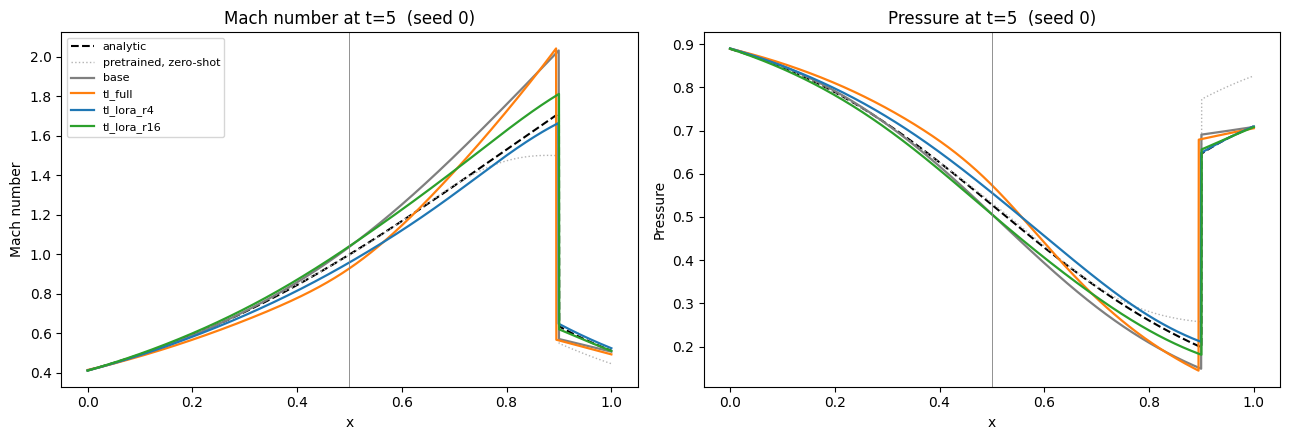

In [13]:
cols = {"base": "tab:gray", "tl_full": "tab:orange", **{f"tl_lora_r{r}": c for r, c in zip(CFG.lora_ranks, ["tab:blue", "tab:green", "tab:purple", "tab:red"])}}
x_grid = np.linspace(X_START, X_END, CFG.n_eval)
ref = PROB_NEW.reference(x_grid)
s0 = CFG.seeds[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key, lab in zip(axes, ("M", "P"), ("Mach number", "Pressure")):
    ax.plot(x_grid, ref[key], "k--", lw=1.5, label="analytic")
    zs = predict_dual(pre.model.derive(results[("base", s0)].meta["x_coarse"]), x_grid, CFG.t_max)
    ax.plot(x_grid, zs[key], color="0.7", lw=1, ls=":", label="pretrained, zero-shot")
    for arm in order:
        ax.plot(x_grid, predict_dual(results[(arm, s0)].model, x_grid, CFG.t_max)[key], color=cols[arm], lw=1.6, label=arm)
    ax.axvline(X_THROAT, color="gray", lw=0.6)
    ax.set_xlabel("x"); ax.set_ylabel(lab); ax.set_title(f"{lab} at t={CFG.t_max:g}  (seed {s0})")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(STORE.root / "profiles.png", dpi=130); plt.show()

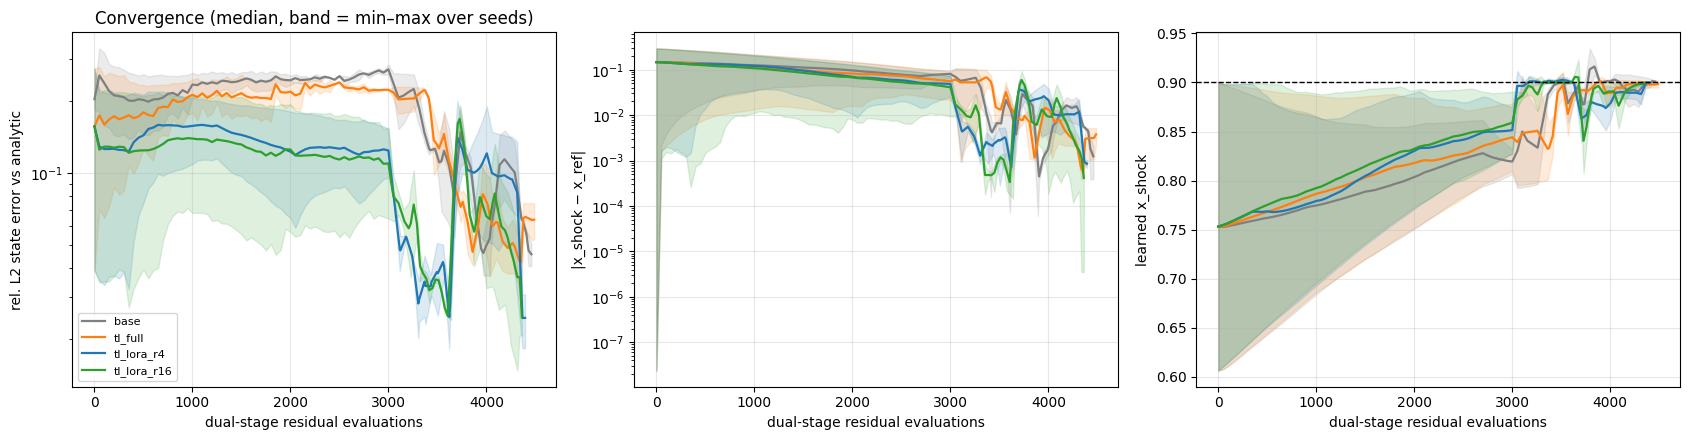

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for arm in order:
    cs = [results[(arm, s)].curve for s in CFG.seeds]
    grid = np.unique(np.concatenate([c["evals"].values for c in cs]))
    for ax, col in zip(axes, ("l2_state", "shock_err", "x_shock")):
        ys = np.stack([np.interp(grid, c["evals"], c[col]) for c in cs])
        ax.plot(grid, np.median(ys, 0), color=cols[arm], label=arm, lw=1.6)
        if len(cs) > 1:
            ax.fill_between(grid, ys.min(0), ys.max(0), color=cols[arm], alpha=0.15)
axes[0].set_yscale("log"); axes[0].set_ylabel("rel. L2 state error vs analytic")
axes[1].set_yscale("log"); axes[1].set_ylabel("|x_shock − x_ref|")
axes[2].axhline(CFG.x_new, color="k", ls="--", lw=1); axes[2].set_ylabel("learned x_shock")
for ax in axes:
    ax.set_xlabel("dual-stage residual evaluations"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8); axes[0].set_title("Convergence (median, band = min–max over seeds)")
plt.tight_layout(); plt.savefig(STORE.root / "convergence.png", dpi=130); plt.show()

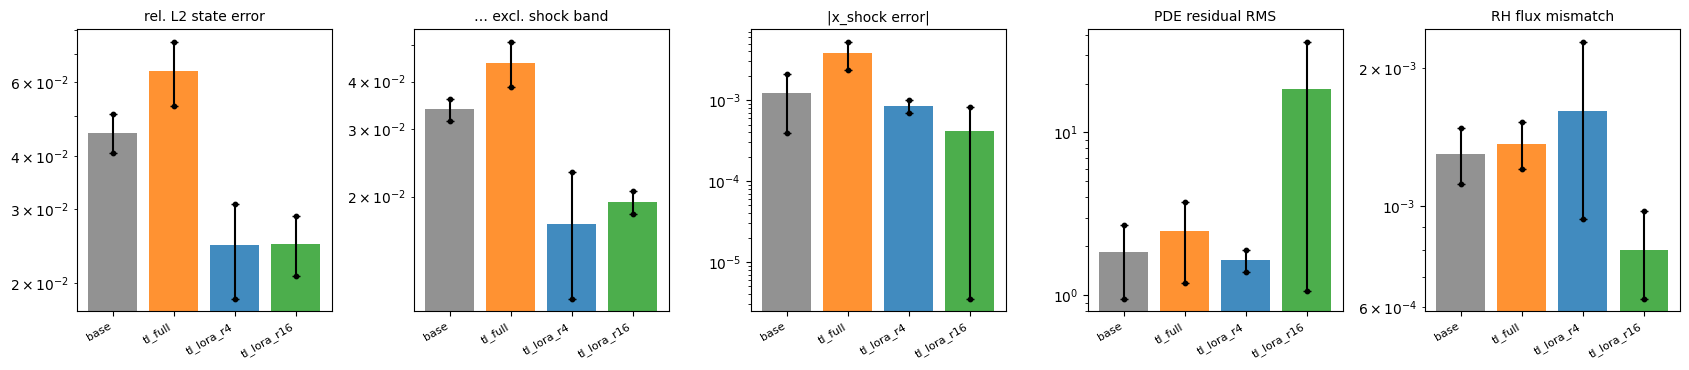

In [15]:
metrics_to_plot = [("l2_state", "rel. L2 state error"), ("l2_state_smooth", "… excl. shock band"),
                   ("shock_err", "|x_shock error|"), ("pde_rms", "PDE residual RMS"), ("rh_resid", "RH flux mismatch")]
fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(3.4 * len(metrics_to_plot), 3.8))
for ax, (col, lab) in zip(axes, metrics_to_plot):
    for i, arm in enumerate(order):
        v = summary[summary.arm == arm][col].values
        ax.bar(i, v.mean(), yerr=v.std() if len(v) > 1 else None, color=cols[arm], alpha=0.85, capsize=3)
        ax.scatter(np.full(len(v), i), v, color="k", s=10, zorder=3)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=30, ha="right", fontsize=8)
    ax.set_yscale("log"); ax.set_title(lab, fontsize=10)
plt.tight_layout(); plt.savefig(STORE.root / "final_metrics.png", dpi=130); plt.show()

## 11. Reusing saved runs
A LoRA run can be restored three ways, all equivalent — demonstrated and checked below:
1. `STORE.load(name)` – full self-describing checkpoint;
2. `STORE.load_dual_from_adapters(name, base_dualmodel)` – pretrained model + the tiny adapter files only;
3. the merged plain checkpoints (`merged_net_*.pt`) – no LoRA code needed at inference time.

In [16]:
r0 = CFG.lora_ranks[0]
name = f"new{CFG.x_new:.2f}_s{s0}_tl_lora_r{r0}"
x_test = np.linspace(X_START, X_END, 500)

full = STORE.load(name).model
pre_loaded = STORE.load(f"pretrained_x{CFG.x_pre:.2f}").model  # the TL asset, straight from disk
from_adapters = STORE.load_dual_from_adapters(name, pre_loaded)
d = STORE.path(name)
merged = DualModel(load_model(d / "merged_net_L.pt")[0], load_model(d / "merged_net_R.pt")[0], full.shock)

ref_pred = predict_dual(full, x_test, CFG.t_max)
for label, dm in [("adapters-only", from_adapters), ("merged plain", merged)]:
    err = max(np.abs(predict_dual(dm, x_test, CFG.t_max)[k] - ref_pred[k]).max() for k in ref_pred)
    print(f"{label:>14}: max |Δ| vs full checkpoint = {err:.2e}")
    assert err < 1e-4

res_l = results[("tl_lora_r%d" % r0, s0)]
print(f"adapter files: {res_l.meta['adapter_bytes'] / 1e3:.1f} kB   vs   full nets: {res_l.meta['full_bytes'] / 1e3:.1f} kB")
print("\nfiles in", d, ":", sorted(p.name for p in d.iterdir()))

 adapters-only: max |Δ| vs full checkpoint = 0.00e+00
  merged plain: max |Δ| vs full checkpoint = 9.54e-07
adapter files: 41.2 kB   vs   full nets: 447.3 kB

files in runs/new0.90_s0_tl_lora_r4 : ['adapter_L.pt', 'adapter_R.pt', 'curve.csv', 'history.csv', 'manifest.json', 'merged_net_L.pt', 'merged_net_R.pt', 'net_L.pt', 'net_R.pt', 'shock.pt']
